# Planta Física: we learn genetic algorithms through four decisions

MA2015.202 · March 2025 · One cumulative notebook.

We build a model, trace one generation and compare two small configurations. Keep your team calculations, code and interpretation here.

# Part 2 · Development submission

**Milestone:** Development · 15 % of the course grade · B1 justified operator modification (70 points) · B2 reproducibility and controlled comparison (30 points).
**Due:** Friday 16 October 2026, 23:59 (Mexico City time).

**Team identification**

| Field | Value |
|---|---|
| Course | MA2015.202 |
| Section / group | 202 |
| Team | Team 04 |
| Member 1 | Omar José Bolaños Valencia · A01668319 |
| Member 2 | Kaige Duan · A01833207 |
| Member 3 | Arturo Emiliano García Fuentes · A01661034 |

**Role rotation for this milestone**

| Role | Member | Student ID |
|---|---|---|
| Driver (code and notebook) | Kaige Duan | A01833207 |
| Reviewer | Omar José Bolaños Valencia | A01668319 |
| Verifier | Arturo Emiliano García Fuentes | A01661034 |

The three roles rotate across milestones, so the driver of one milestone acts as reviewer or verifier in the next one. This is the cumulative notebook: the supplied base is kept, apart from the single documented crossover parameter of Section 8b and every section below holds the team evidence next to the base material it belongs to. All code cells were executed from top to bottom with the supplied environment files and the outputs are retained in the file.

## Team changes and versions (Development milestone)

All our team had done in variant is to change the crossover from one point crossover to uniform crossover, which can be seen at Section-8b. And to compare Baseline and Variant, we rewrote Section 9-11 for comparison. The supplied $p_m=0.25$ vs $0.50$ comparison was temporarily removed. It belongs to the Final milestone and will be re-added there with the identified code.

## 1. We define the problem

We assign a treated-water fraction to each building to reduce potable-water use. We use actual aggregate demands from March 2025: Aulas 1 = 847, Biblioteca = 462, Cedetec = 284.21 and Aulas 2 = 683 m³, in this order. None of these four records is flagged as imputed, zero or anomalous.

We adopt 1,410 m³ as a **teaching capacity assumption** from the existing calibration, not a capacity confirmed by the partner. We also treat building limits as teaching assumptions.

We encode $k=(k_1,k_2,k_3,k_4)$ as integers: $k_1,k_2,k_4\in\{0,\ldots,8\}$ and $k_3\in\{0,\ldots,6\}$. We interpret $x_i=k_i/10$. Gene 6 means 60% reuse. There are $9\times9\times7\times9=5103$ combinations; we explore some of them with a genetic algorithm.

In [1]:
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])  # m3, March 2025
LIMITS = np.array([8, 8, 6, 8])  # integer levels; fractions = levels / 10
CAPACITY = 1410.0  # m3; teaching assumption, not confirmed plant capacity

## 1.1 A1 · Formulation, domains, units, objective and capacity

**Chromosome order.** The four genes keep the order of the supplied demand table and we never reorder them.

| Gene | Building | Observed demand $D_i$ (m³) | Domain | Reuse fraction $x_i$ | Treated volume $T_i$ (m³) |
|---|---|---|---|---|---|
| $k_1$ | Aulas 1 | 847.00 | $\{0,\ldots,8\}$ | $k_1/10$ | $847.00\,k_1/10$ |
| $k_2$ | Biblioteca | 462.00 | $\{0,\ldots,8\}$ | $k_2/10$ | $462.00\,k_2/10$ |
| $k_3$ | Cedetec | 284.21 | $\{0,\ldots,6\}$ | $k_3/10$ | $284.21\,k_3/10$ |
| $k_4$ | Aulas 2 | 683.00 | $\{0,\ldots,8\}$ | $k_4/10$ | $683.00\,k_4/10$ |

**What each gene means.** $k_i$ is the integer reuse level assigned to building $i$, and the physical fraction is $x_i = k_i/10$, so one step of a gene is ten percentage points. The fraction $x_i$ is the share of that building's demand met with treated water instead of potable water. For example $k_3 = 6$ means 60 % reuse in Cedetec. Because the domains are discrete, only multiples of 10 % are representable, and the search space holds $9 \times 9 \times 7 \times 9 = 5103$ chromosomes.

**Total demand (observed).**

$$\sum_{i=1}^{4} D_i = 847.00 + 462.00 + 284.21 + 683.00 = 2276.21 \ \text{m}^3$$

**Decision variables, objective, units and capacity.** Each building contributes a treated volume $T_i = D_i\,k_i/10$, and the aggregate quantities are sums of those four terms:

$$T(k) = \sum_{i=1}^{4} T_i = \sum_{i=1}^{4} D_i \frac{k_i}{10} \ \text{[m}^3\text{]} \qquad \text{treated water used}$$

$$P(k) = 2276.21 - T \ \text{[m}^3\text{]} \qquad \text{potable water still required}$$

$$E(k) = \max(0,\ T - 1410) \ \text{[m}^3\text{]} \qquad \text{excess over capacity}$$

$$F(k) = \begin{cases} P/2276.21, & T \le 1410 \\ 1 + E/1410, & T > 1410 \end{cases} \qquad \text{dimensionless}$$

We minimise $P$ subject to the gene domains and to $T \le C$ with $C = 1410$ m³. We rank candidates with the scalar fitness $F$, and **lower is better**. For a feasible candidate $F$ is exactly the fraction of the total demand that must still be met with potable water, so $F \le 1$; for an infeasible candidate $F > 1$. The evaluator tests $T \le C$ with a numerical tolerance of $10^{-8}$ m³.

**Observed data versus teaching assumptions.**

| Element | Origin | Status |
|---|---|---|
| Demands 847.00, 462.00, 284.21, 683.00 m³ | Four March 2025 records of the supplied water-consumption data | Observed data |
| Total demand 2276.21 m³ | Sum of the four observed records | Derived from observed data |
| Capacity $C = 1410$ m³ | Instructor calibration of the supplied parameters file | Teaching assumption |
| Domains $\{0..8\}$, $\{0..8\}$, $\{0..6\}$, $\{0..8\}$ | Given with the challenge | Teaching assumption |

We treat $C = 1410$ m³ and the four building limits as teaching assumptions of this exercise: they come from the instructor's calibration of the supplied parameters, not from a partner-confirmed plant capacity, so we never present them as a property that the campus can satisfy. The four source records have no imputation, no zero value and no possible-anomaly flag, so we use them directly and we neither impute nor repair them. The code rejects invalid encodings instead of silently rounding or fixing them: `evaluate` raises an error when the chromosome is not four integers or when a gene leaves its domain.

**Domains and capacity are two different constraints.** The domains bound each $k_i$ on its own; the capacity bounds the four buildings together. A chromosome can be perfectly valid and still be infeasible, which is exactly what happens to the maximum plan analysed in section 2.2.

## 2. We calculate water use and fitness

We define treated water $T=\sum_iD_i k_i/10$, potable water $P=\sum_iD_i-T$ and excess $E=\max(0,T-C)$. We minimize $P$ subject to the domains and $T\le C$.

We rank candidates with $F=P/\sum D_i$ when feasible and $F=1+E/C$ when over capacity. **Lower fitness is better.** Feasible candidates have $F\le1$; infeasible candidates have $F>1$. We use a numerical tolerance of $10^{-8}$ m³.

Before running the code, calculate $k=(6,6,6,6)$ by hand: $T=0.6(2276.21)=1365.726$, $P=910.484$, $E=0$, $F=0.4$. Explain why it respects capacity and state the units.

## 2.1 A2 · Hand calculation of one candidate, $k = (6,6,6,6)$

We do this arithmetic by hand, before reading the code output. A uniform 60 % reuse means $k_i/10 = 0.6$ for the four buildings, so each treated volume is one product:

| Building | Product | $T_i$ (m³) | $P_i = D_i - T_i$ (m³) | Row check $T_i + P_i$ (m³) |
|---|---|---|---|---|
| Aulas 1 | $0.6 \times 847.00$ | 508.200 | 338.800 | 847.00 |
| Biblioteca | $0.6 \times 462.00$ | 277.200 | 184.800 | 462.00 |
| Cedetec | $0.6 \times 284.21$ | 170.526 | 113.684 | 284.21 |
| Aulas 2 | $0.6 \times 683.00$ | 409.800 | 273.200 | 683.00 |

$$T = \sum_{i=1}^{4} T_i = 0.6(847.00) + 0.6(462.00) + 0.6(284.21) + 0.6(683.00) = 508.2 + 277.2 + 170.526 + 409.8 = 1365.726 \ \text{m}^3$$

$$P = 2276.21 - 1365.726 = 910.484 \ \text{m}^3$$

$$E = \max(0,\ 1365.726 - 1410) = \max(0,\ -44.274) = 0 \ \text{m}^3$$

$$F = \frac{P}{2276.21} = \frac{910.484}{2276.21} = 0.4$$

**Units.** $T$, $P$ and $E$ are volumes in m³; $F$ is dimensionless because it is a ratio of two volumes.

**Why the capacity is satisfied.** $T = 1365.726$ m³ is below $C = 1410$ m³, so the plan leaves $1410 - 1365.726 = 44.274$ m³ of unused capacity, the excess is $E = 0$ and the candidate is feasible with $F = 0.4 < 1$. Read as percentages, 60 % of the total demand is covered with treated water and the remaining 40 % still needs potable water.

In [2]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)
    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")
    treated = float(np.sum(DEMAND * genes / 10))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8  # numerical tolerance in m3
    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY
    return dict(treated=treated, potable=potable, excess=excess,
                feasible=feasible, fitness=fitness)

Check three candidates: zero reuse, uniform 60% and domain maxima. Distinguish valid gene domains from capacity feasibility. The keys `treated`, `potable`, `excess`, `feasible` and `fitness` represent $T$, $P$, $E$, feasibility and $F$.

In [3]:
cases = [np.zeros(4, dtype=int), np.array([6, 6, 6, 6]), LIMITS.copy()]
for genes in cases:
    print(genes, evaluate(genes))
assert np.isclose(evaluate(cases[1])["potable"], 910.484)
assert evaluate(cases[1])["feasible"]
assert not evaluate(cases[2])["feasible"]

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[6 6 6 6] {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
[8 8 6 8] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


In [4]:
# A2 evidence: the same arithmetic, next to the evaluator output printed above.
def building_table(genes, title):
    """Print the four products, the row check T_i + P_i = D_i and the totals."""
    print(title)
    print(f"{'Building':<11}{'D_i':>9}{'k_i':>4}{'x_i':>6}{'T_i':>10}{'P_i':>10}{'T_i+P_i':>11}{'ok':>6}")
    total_t = total_p = 0.0
    for name, demand, gene in zip(BUILDINGS, DEMAND, genes):
        fraction = gene / 10
        treated_i = demand * fraction
        potable_i = demand - treated_i
        total_t += treated_i
        total_p += potable_i
        ok = np.isclose(treated_i + potable_i, demand)
        print(f"{name:<11}{demand:>9.2f}{gene:>4d}{fraction:>6.1f}"
              f"{treated_i:>10.3f}{potable_i:>10.3f}{treated_i + potable_i:>11.3f}{str(ok):>6}")
    excess = max(0.0, total_t - CAPACITY)
    print(f"{'TOTAL':<11}{float(np.sum(DEMAND)):>9.2f}{'':>4}{'':>6}"
          f"{total_t:>10.3f}{total_p:>10.3f}{total_t + total_p:>11.3f}")
    print(f"  T = {total_t:.3f} m3 | P = {total_p:.3f} m3 | E = {excess:.3f} m3"
          f" | feasible = {excess <= 1e-8}")
    print()


building_table(np.array([6, 6, 6, 6]), "k = (6, 6, 6, 6)   hand calculation and evaluator")
building_table(LIMITS.copy(), "k = (8, 8, 6, 8)   domain maxima")

# Hand calculation compared with the keys returned by evaluate().
metrics = evaluate(np.array([6, 6, 6, 6]))
hand = {"treated": 1365.726, "potable": 910.484, "excess": 0.0, "fitness": 0.4}
print(f"{'key':<9}{'by hand':>12}{'evaluator':>20}{'hand-eval':>13}")
for key, value in hand.items():
    got = float(metrics[key])
    print(f"{key:<9}{value:>12.6f}{got:>20.13f}{value - got:>13.2e}")
print(f"{'feasible':<9}{str(True):>12}{str(metrics['feasible']):>20}{'-':>13}")

# The corrected maximum case: potable 512.084 m3, excess 354.126 m3, F = 1.251153.
worst = evaluate(LIMITS.copy())
assert np.isclose(worst["potable"], 512.084, atol=1e-9)
assert np.isclose(worst["excess"], 354.126, atol=1e-9)
assert np.isclose(worst["fitness"], 1.251153, atol=1e-6)
assert not worst["feasible"]
print()
print("Maximum case checked: P = %.3f m3, E = %.3f m3, F = %.6f"
      % (worst["potable"], worst["excess"], worst["fitness"]))

k = (6, 6, 6, 6)   hand calculation and evaluator
Building         D_i k_i   x_i       T_i       P_i    T_i+P_i    ok
AULAS 1       847.00   6   0.6   508.200   338.800    847.000  True
BIBLIOTECA    462.00   6   0.6   277.200   184.800    462.000  True
CEDETEC       284.21   6   0.6   170.526   113.684    284.210  True
AULAS 2       683.00   6   0.6   409.800   273.200    683.000  True
TOTAL        2276.21            1365.726   910.484   2276.210
  T = 1365.726 m3 | P = 910.484 m3 | E = 0.000 m3 | feasible = True

k = (8, 8, 6, 8)   domain maxima
Building         D_i k_i   x_i       T_i       P_i    T_i+P_i    ok
AULAS 1       847.00   8   0.8   677.600   169.400    847.000  True
BIBLIOTECA    462.00   8   0.8   369.600    92.400    462.000  True
CEDETEC       284.21   6   0.6   170.526   113.684    284.210  True
AULAS 2       683.00   8   0.8   546.400   136.600    683.000  True
TOTAL        2276.21            1764.126   512.084   2276.210
  T = 1764.126 m3 | P = 512.084 m3 | E = 354

We interpret the results: the maximum plan uses 1764.126 m³ of treated water, exceeds capacity by 354.126 m³ and receives $F>1$. Although it uses less potable water, we reject it as infeasible. Retain your team hand calculation and explanation as Research evidence.

## 2.2 A2 · Check against the evaluator and interpretation of the maximum case

**Hand calculation compared with the evaluator.** The check-candidate cell above prints the dictionary returned by `evaluate([6, 6, 6, 6])`, and the A2 evidence cell repeats it next to the arithmetic of section 2.1. The table below adds a column with the difference between the two, computed as hand minus evaluator.

| Quantity | Key returned by `evaluate` | By hand | Evaluator | Difference (hand − evaluator) | Agrees |
|---|---|---|---|---|---|
| Treated water (m³) | `treated` | 1365.726 | 1365.7259999999999 | $+2.3 \times 10^{-13}$ | yes |
| Potable water (m³) | `potable` | 910.484 | 910.4840000000002 | $-1.1 \times 10^{-13}$ | yes |
| Excess over capacity (m³) | `excess` | 0 | 0.0 | 0 | yes |
| Feasibility | `feasible` | True | True | — | yes |
| Fitness (dimensionless) | `fitness` | 0.4 | 0.4000000000000001 | $-5.6 \times 10^{-17}$ | yes |

The evaluator agrees with the hand calculation, and the agreement is not a coincidence: `evaluate` implements exactly the equations of section 1.1 by multiplying each demand by $k_i/10$ and then summing, so it adds the same four products we added by hand. The last digits differ only because the fractions are stored in binary floating point; every difference is at the $10^{-13}$ level or smaller, far below the $10^{-8}$ m³ tolerance used by the code, and that is why the assertion `np.isclose(..., 910.484)` passes.

**Why the maximum plan is infeasible although every gene is valid.** The case `LIMITS` is $k = (8,8,6,8)$, the largest level allowed in each domain.

$$T = 0.8(847.00) + 0.8(462.00) + 0.6(284.21) + 0.8(683.00) = 677.6 + 369.6 + 170.526 + 546.4 = 1764.126 \ \text{m}^3$$

$$P = 2276.21 - 1764.126 = 512.084 \ \text{m}^3$$

$$E = 1764.126 - 1410 = 354.126 \ \text{m}^3 \qquad F = 1 + \frac{354.126}{1410} = 1.251153\ldots$$

Every gene is inside its own domain, so the encoding is valid and the evaluator does not reject it for that reason. What fails is the capacity constraint that links the four buildings, because $T = 1764.126$ m³ exceeds the capacity by $E = 354.126$ m³. The plan is therefore infeasible and we reject it, even though it reaches the smallest potable volume available in the whole domain, $P = 512.084$ m³. This is the difference between a valid chromosome and a feasible solution, and it is why the fitness of an infeasible candidate is pushed above 1 instead of being ranked against the feasible ones.

**Consequence for the model.** Because the feasible region requires $T \le 1410$, the potable water can never drop below $2276.21 - 1410 = 866.21$ m³, a fraction $866.21/2276.21 = 0.3805\ldots$ of the total demand. No chromosome can do better than about 38.05 % potable water under this capacity, and the discrete domains keep the attainable values slightly above that bound.

## 3. We generate a population

A population is a list of candidates. We sample each gene within its domain, including both endpoints. Sampling does not guarantee capacity feasibility; fitness also ranks infeasible candidates. We fix a seed to reproduce this demonstration.

In [5]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)

rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[0 6 4 3] 0.7382561362967388
[3 7 0 6] 0.5662526744017468
[1 0 3 8] 0.6852825530157587
[6 6 5 7] 0.38248008751389373


## 4. We select parents through tournaments

We sample two distinct candidates and select the lower $F$. We repeat to obtain another parent; one individual may win several tournaments. Selection favors low fitness without always sorting the population. We return a copy to protect the original.

In [6]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()

parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[3 7 0 6] [3 7 0 6]


## 5. We combine information through one-point crossover

We choose a cut between positions and combine the start of one parent with the end of the other. Building positions remain fixed. Parents $(6,6,6,6)$ and $(8,2,4,3)$ with cut 2 produce $(6,6,4,3)$. Crossover preserves domains but may exceed capacity.

In [7]:
def crossover(parent_a: np.ndarray, parent_b: np.ndarray,
              rng: np.random.Generator) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))

child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[3 7 0 6] {'treated': 987.3, 'potable': 1288.91, 'excess': 0.0, 'feasible': True, 'fitness': 0.5662526744017468}


## 6. We introduce variation through mutation

We apply the probability to **each gene**, not the entire chromosome. Each selected gene moves up or down one valid level. At zero we can only move up; at the maximum we can only move down. With $p=0.25$ and four genes, the expected number of selected genes is one per child, not exactly one. Mutation may improve or worsen fitness.

In [8]:
def mutate(child: np.ndarray, probability: float,
           rng: np.random.Generator) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result

mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[3 7 0 6] [3 7 0 7] {'treated': 1055.6, 'potable': 1220.6100000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.5362466556249205}


## 7. We replace the population and retain one elite

We copy the best individual unchanged and fill the remaining positions with offspring. Population size stays constant. Elitism prevents losing the best fitness; it does not prove optimality. Independent copies prevent offspring changes from modifying parents or the elite.

*Team change:* `next_generation` receives the crossover operator as `crossover_op`. Its default is the supplied one-point `crossover`, so calls without it behave exactly like the base.

In [9]:
def next_generation(population: list, probability: float,
                    rng: np.random.Generator, crossover_op=crossover) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover_op(parent_a, parent_b, rng)  # team: operator is a parameter
        replacement.append(mutate(child, probability, rng))
    return replacement

replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.38248008751389373
0.38248008751389373


## 8. We complete the loop

We initialize and evaluate, then repeat selection, crossover, mutation and replacement for a fixed number of generations. We record the initial best $F$ and the best after each generation. Twenty generations produce 21 values, including initialization. We do not expect improvement at every step.

In [10]:
def run_ga(population_size: int = 20, generations: int = 20,
           mutation_probability: float = 0.25, seed: int = 42,
           crossover_op=crossover) -> dict:
    """Run a small canonical GA and retain the best fitness at each generation."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng, crossover_op)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

## 8b. Development: uniform crossover variant (team change)

The baseline crossover is one-point crossover: it draws a cut point from $\{1,2,3\}$ and builds the child as $A[:cut]$ concatenated with $B[cut:]$, so every gene before the cut is inherited from parent A and every gene after it from parent B. With only four genes that fixed split has two consequences we did not want. First, the child always takes Aulas 1 ($k_1$) from A and Aulas 2 ($k_4$) from B, so the two largest demands (847 and 683 m³, 67 % of the monthly total) can never be inherited together from the same parent, and only 3 of the 14 non-trivial inheritance patterns are reachable at all. Second, neighbouring genes are forced to travel together even though the order of the buildings in the chromosome is arbitrary and carries no physical meaning. Our improvement is to stop deciding inheritance at a single cut and decide it building by building instead, and that is exactly what uniform crossover does: for each of the four genes we flip a fair coin and copy that gene either from parent A or from parent B, which yields $16$ possible inheritance masks in place of $3$. The three children of one-point crossover are still a subset of those 16, so the change adds reachable children without removing any, and every child gene still comes from the same position of a valid parent, so the domains are preserved. Capacity is still checked only by `evaluate`: we add no repair and no rounding, and a child that goes over the capacity simply receives $F=1+E/C>1$. Our hypothesis is that this finer per-building exchange lets a good plan trade levels between buildings near $C=1410$ m³, and therefore reaches an equal or lower best $F$ than the baseline under the same 20 generations, seed 42 and $p_m=0.25$.

In [11]:
from itertools import product


def uniform_crossover(parent_a: np.ndarray, parent_b: np.ndarray,
                      rng: np.random.Generator) -> np.ndarray:
    """Team variant: inherit each gene independently from A or B with probability 0.5."""
    mask = rng.random(len(LIMITS)) < 0.5  # True -> gene from parent_a, False -> parent_b
    return np.where(mask, parent_a, parent_b)


# Demonstration with the parents used in Section 5.
pa, pb = np.array([6, 6, 6, 6]), np.array([8, 2, 4, 3])
child_uniform = uniform_crossover(pa, pb, np.random.default_rng(42))
origin = ["A" if a == c else "B" for a, c in zip(pa, child_uniform)]
print("uniform child:", child_uniform, "genes from", origin, evaluate(child_uniform))

# Limitation made visible: every child each operator can produce from these parents.
one_point = {tuple(int(g) for g in np.concatenate((pa[:cut], pb[cut:]))) for cut in range(1, len(LIMITS))}
uniform = {tuple(int(g) for g in np.where(np.array(m, dtype=bool), pa, pb))
           for m in product((0, 1), repeat=len(LIMITS))}
print(f"one-point reachable children: {len(one_point)}, uniform reachable children: {len(uniform)} (incl. both parents)")
for genes in sorted(one_point):
    print("  one-point:", genes, "F =", round(evaluate(np.array(genes))["fitness"], 5))
uniform_only = uniform - one_point - {tuple(int(g) for g in pa), tuple(int(g) for g in pb)}
best_new = min(uniform_only, key=lambda g: evaluate(np.array(g))["fitness"])
print("  best child only uniform can produce:", best_new,
      "F =", round(evaluate(np.array(best_new))["fitness"], 5))
assert one_point <= uniform  # uniform can still produce every one-point child
assert all(np.all((0 <= np.array(g)) & (np.array(g) <= LIMITS)) for g in uniform)

uniform child: [8 6 4 3] genes from ['B', 'A', 'B', 'B'] {'treated': 1273.384, 'potable': 1002.826, 'excess': 0.0, 'feasible': True, 'fitness': 0.4405683131169795}
one-point reachable children: 3, uniform reachable children: 16 (incl. both parents)
  one-point: (6, 2, 4, 3) F = 0.59618
  one-point: (6, 6, 4, 3) F = 0.51499
  one-point: (6, 6, 6, 3) F = 0.49002
  best child only uniform can produce: (8, 2, 6, 6) F = 0.40677


### Tracing one variant generation

We trace a single generation of the variant on the four-individual seed-42 demo population with $p_m=0.25$. The surrounding steps are the supplied ones we left untouched: elitism copies the best individual into slot 0, two independent tournaments of two supply the parents, mutation moves each gene by $\pm1$ level with probability 0.25 inside its domain, and the children fill the remaining slots until the population size is restored. The step we focus on is crossover, because it is the operator we replaced: instead of cutting the chromosome once, the variant flips a coin per building, so each child gene is inherited independently, and the printed trace labels every gene with the parent it came from (`=`, A or B). Finally we assert that this manual trace is identical to `next_generation(..., crossover_op=uniform_crossover)` under the same random state, so this explanation describes the code that actually ran.

In [12]:
def show(label: str, genes: np.ndarray) -> None:
    m = evaluate(genes)
    print(f"{label:<26}{genes}  T={m['treated']:8.3f} m3  F={m['fitness']:.5f}  feasible={m['feasible']}")


rng_trace = np.random.default_rng(42)
population_trace = [random_individual(rng_trace) for _ in range(4)]
for i, genes in enumerate(population_trace):
    show(f"current[{i}]", genes)

elite = min(population_trace, key=lambda x: evaluate(x)["fitness"]).copy()
new_population = [elite]
show("-> elite kept in slot 0", elite)
while len(new_population) < len(population_trace):
    print(f"--- building slot {len(new_population)}")
    parent_a = tournament(population_trace, rng_trace)
    parent_b = tournament(population_trace, rng_trace)
    show("tournament winner A", parent_a)
    show("tournament winner B", parent_b)
    child = uniform_crossover(parent_a, parent_b, rng_trace)
    origin = ["=" if a == b else ("A" if a == c else "B") for a, b, c in zip(parent_a, parent_b, child)]
    show(f"uniform child {''.join(origin)}", child)
    mutant = mutate(child, 0.25, rng_trace)
    show("after mutation", mutant)
    new_population.append(mutant)

# The manual trace must equal the function used in the experiments.
rng_check = np.random.default_rng(42)
population_check = [random_individual(rng_check) for _ in range(4)]
replacement_check = next_generation(population_check, 0.25, rng_check, uniform_crossover)
for traced, produced in zip(new_population, replacement_check):
    np.testing.assert_array_equal(traced, produced)
assert len(replacement_check) == len(population_check)                       # fixed size
assert all(np.all((0 <= g) & (g <= LIMITS)) for g in replacement_check)      # valid domains
np.testing.assert_array_equal(replacement_check[0], elite)                   # elite protected
assert min(evaluate(g)["fitness"] for g in replacement_check) <= evaluate(elite)["fitness"]
print("Trace equals next_generation; size, domains and elite checked.")

current[0]                [0 6 4 3]  T= 595.784 m3  F=0.73826  feasible=True
current[1]                [3 7 0 6]  T= 987.300 m3  F=0.56625  feasible=True
current[2]                [1 0 3 8]  T= 716.363 m3  F=0.68528  feasible=True
current[3]                [6 6 5 7]  T=1405.605 m3  F=0.38248  feasible=True
-> elite kept in slot 0   [6 6 5 7]  T=1405.605 m3  F=0.38248  feasible=True
--- building slot 1
tournament winner A       [3 7 0 6]  T= 987.300 m3  F=0.56625  feasible=True
tournament winner B       [3 7 0 6]  T= 987.300 m3  F=0.56625  feasible=True
uniform child ====        [3 7 0 6]  T= 987.300 m3  F=0.56625  feasible=True
after mutation            [2 8 0 6]  T= 948.800 m3  F=0.58317  feasible=True
--- building slot 2
tournament winner A       [6 6 5 7]  T=1405.605 m3  F=0.38248  feasible=True
tournament winner B       [3 7 0 6]  T= 987.300 m3  F=0.56625  feasible=True
uniform child BBAA        [3 7 5 7]  T=1197.705 m3  F=0.47382  feasible=True
after mutation            [4 7 5 7] 

## 9. Development comparison: base vs variant under identical conditions

| Condition | Base | Variant |
|---|---|---|
| Data, domains, capacity $C$ | March 2025, (8,8,6,8), 1410 m³ | same |
| Population / generations | 20 / 20 | same |
| Mutation | per-gene ±1, $p_m=0.25$ | same |
| Selection / replacement / elitism | tournament of 2 / generational / 1 elite | same |
| Seed | 42 (fresh `default_rng(42)` inside each `run_ga`) | same |
| **Crossover** | **one-point** (`crossover`) | **uniform** (`uniform_crossover`) |

Each run starts from scratch inside `run_ga`, so no state is shared between versions. Both draw the same initial population (seed 42). As a **reference only**, we also enumerate all 5103 plans to find the true optimum. That is possible only because this teaching case is tiny; it is not part of the GA.

In [13]:
import platform
import matplotlib

DEV_CONFIG = dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)
VERSIONS = {"Base (one-point)": crossover, "Variant (uniform)": uniform_crossover}
results = {label: run_ga(**DEV_CONFIG, crossover_op=op) for label, op in VERSIONS.items()}

all_plans = [np.array(k) for k in product(*(range(limit + 1) for limit in LIMITS))]
optimum = min(all_plans, key=lambda k: evaluate(k)["fitness"])
reference = dict(genes=optimum, metrics=evaluate(optimum), history=None)


def last_improvement(history) -> str:
    drops = np.flatnonzero(np.diff(history) < -1e-12)
    return str(int(drops[-1]) + 1) if drops.size else "none"


print(f"Python {platform.python_version()} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")
print("Config:", DEV_CONFIG, "| feasible plans:",
      sum(evaluate(k)["feasible"] for k in all_plans), "of", len(all_plans))
header = f"{'version':<22}{'genes':<14}{'fractions %':<18}{'T m3':>10}{'P m3':>10}{'E m3':>7}{'feas.':>7}{'F':>10}{'P-P* m3':>9}{'last gen':>9}"
print(header)
print("-" * len(header))
for label, r in [*results.items(), ("Optimum (reference)", reference)]:
    m = r["metrics"]
    gap = m["potable"] - reference["metrics"]["potable"]
    gen = last_improvement(r["history"]) if r["history"] is not None else "-"
    print(f"{label:<22}{str(tuple(int(g) for g in r['genes'])):<14}"
          f"{str(tuple(int(g) * 10 for g in r['genes'])):<18}"
          f"{m['treated']:>10.3f}{m['potable']:>10.3f}{m['excess']:>7.3f}{str(m['feasible']):>7}"
          f"{m['fitness']:>10.5f}{gap:>9.3f}{gen:>9}")

base, variant = results["Base (one-point)"], results["Variant (uniform)"]
print(f"\nVariant - base: potable {variant['metrics']['potable'] - base['metrics']['potable']:+.3f} m3, "
      f"F {variant['metrics']['fitness'] - base['metrics']['fitness']:+.6f}")

Python 3.12.4 | NumPy 2.3.5 | Matplotlib 3.11.2
Config: {'population_size': 20, 'generations': 20, 'mutation_probability': 0.25, 'seed': 42} | feasible plans: 4875 of 5103
version               genes         fractions %             T m3      P m3   E m3  feas.         F  P-P* m3 last gen
--------------------------------------------------------------------------------------------------------------------
Base (one-point)      (7, 4, 3, 8)  (70, 40, 30, 80)    1409.363   866.847  0.000   True   0.38083    0.621       17
Variant (uniform)     (6, 4, 6, 8)  (60, 40, 60, 80)    1409.926   866.284  0.000   True   0.38058    0.058        8
Optimum (reference)   (8, 6, 4, 5)  (80, 60, 40, 50)    1409.984   866.226  0.000   True   0.38056    0.000        -

Variant - base: potable -0.563 m3, F -0.000247


## 10. We visualize and interpret

We read generation on the horizontal axis and best fitness on the vertical axis. A drop means improvement; a plateau means that the elite is retained and no better child appeared. The dashed line is the exhaustive optimum (reference only). A decreasing curve alone does not prove physical validity, so we read it together with the table above.

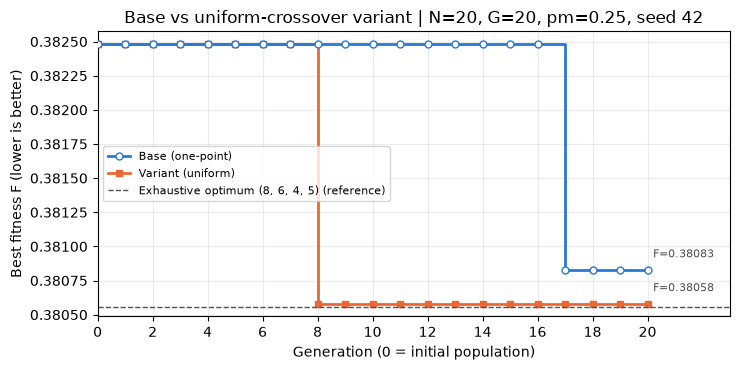

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7.5, 3.8))
# Base drawn on top with hollow markers so it stays visible where both curves coincide.
styles = {"Base (one-point)": dict(color="#2a78d6", marker="o", markerfacecolor="white", zorder=3),
          "Variant (uniform)": dict(color="#eb6834", marker="s", zorder=2)}
for label, r in results.items():
    h = r["history"]
    ax.step(range(len(h)), h, where="post", linewidth=2, markersize=5, label=label, **styles[label])
    ax.annotate(f"F={h[-1]:.5f}", (len(h) - 1, h[-1]), xytext=(4, 7), textcoords="offset points",
                va="bottom", fontsize=8, color="#52514e")
ax.axhline(reference["metrics"]["fitness"], color="#52514e", linestyle="--", linewidth=1,
           label=f"Exhaustive optimum {tuple(int(g) for g in optimum)} (reference)")
ax.set(xlabel="Generation (0 = initial population)", ylabel="Best fitness F (lower is better)",
       title="Base vs uniform-crossover variant | N=20, G=20, pm=0.25, seed 42", xlim=(0, 23))
ax.set_xticks(range(0, 21, 2))
ax.grid(alpha=0.25)
ax.legend(fontsize=8, loc="center left")
fig.tight_layout()
plt.show()

### Team interpretation of the Development comparison

**Part 1 · Comparison of the two runs.**

- Both versions start from the same seed-42 population, whose best individual is (6,6,5,7) with $F=0.38248$.
- Final chromosomes and fractions: the base ends at **(7,4,3,8)** = 70 / 40 / 30 / 80 % and the variant ends at **(6,4,6,8)** = 60 / 40 / 60 / 80 %.
- Treated water: $T_{base}=1409.363$ m³ and $T_{variant}=1409.926$ m³, both just below the 1410 m³ capacity, which is what we expect when potable water is minimised.
- Potable water: $P_{base}=866.847$ m³ against $P_{variant}=866.284$ m³, so the variant needs **0.563 m³ less** potable water in March 2025.
- Excess and feasibility: both final plans are feasible with $E=0$ and $F\le1$.
- Fitness: the variant reaches **0.38058** (its first improvement at generation 8) and the base reaches **0.38083** (its first improvement at generation 17). Both stay above the exhaustive optimum of 0.38056, reached by (8,6,4,5): the gaps are 0.058 m³ and 0.621 m³ of potable water.
- The difference between the two final plans is one level of Aulas 1 traded for three levels of Cedetec: $-84.7$ m³ and $+85.263$ m³.

**Part 2 · Conclusion.**

The only change between the two runs is the crossover operator, and under these fixed conditions (20 individuals, 20 generations, $p_m=0.25$, seed 42) the uniform variant reached a lower final fitness and improved earlier, which supports our hypothesis for this run. We keep that result in proportion. The physical gain is 0.563 m³ in one month, about 0.025 % of the total demand, which is far smaller than the uncertainty of monthly metered data, so operationally the two plans are equivalent; a single seed cannot show that uniform crossover is better in general, because another seed could tie or reverse the order; and the benchmark itself rests on teaching assumptions (the 1410 m³ capacity, the building limits and one month of aggregated demand). The conclusion therefore applies to this controlled comparison inside the academic model, not to a validated hydraulic or sanitary allocation.

## 11. Check reproduction

We repeat **both** versions with the same configuration and check identical genes and histories. We also check that the best fitness never worsens (elitism). Finally, we check that calling `run_ga` *without* `crossover_op` still reproduces the supplied base output (7,4,3,8): the team edit did not change the baseline. Restart the kernel and run top to bottom to exclude hidden state. These repetitions are technical checks, not extra experimental configurations.

In [15]:
for label, op in VERSIONS.items():
    repeated = run_ga(**DEV_CONFIG, crossover_op=op)
    np.testing.assert_array_equal(results[label]["genes"], repeated["genes"])
    np.testing.assert_array_equal(results[label]["history"], repeated["history"])
    assert np.all(np.diff(results[label]["history"]) <= 1e-12), label  # elitism: never worse

default_run = run_ga(**DEV_CONFIG)  # no crossover_op -> supplied one-point crossover
np.testing.assert_array_equal(default_run["history"], base["history"])
np.testing.assert_array_equal(default_run["genes"], [7, 4, 3, 8])  # supplied kit output
print("Both versions reproduced; elitism checked; base default unchanged.")

Both versions reproduced; elitism checked; base default unchanged.


## 12. Retain evidence in the same notebook

- **Research (15%)**: formulation and assumptions (60/100); hand calculation checked against the evaluator (40/100).
- **Development (15%)**: working cycle and operators (70/100); one reproducible, interpreted run (30/100).
- **Final submission (30%)**: explanation of one generation (40/100); two configurations and plot (35/100); physical interpretation and limits (25/100).

Reuse earlier sections and add your team explanation to the final submission. Identify the shared base and any team changes. Additional features are unnecessary for a grade of 100. Retain the supplied environment files with the notebook. Joint code assessment contributes 10% and the individual article examination 30%. Consult levels and dates in the [guide](challenge_guide_planta_fisica.pdf).

**Where our evidence is:** Research → section *Research evidence* (provisional). Development → *Team changes and versions*, Section 8b (limitation, hypothesis, operator, traced generation) and Sections 9–11 (controlled comparison, plot, interpretation, reproduction).

## 13. Research evidence (Part 1)

The Research evidence that used to live in a separate report is now inside this notebook, next to the base section it belongs to.

| Criterion | Where it is in this notebook |
|---|---|
| A1 · order, domains, units, objective and capacity | Section 1.1 |
| A1 · observed data distinguished from teaching assumptions | Section 1.1 (tables and the paragraph on assumptions) |
| A1 · explanation of what each gene means | Section 1.1 |
| A2 · arithmetic for one candidate, calculated by hand | Section 2.1 (four products and the row checks $T_i + P_i = D_i$) |
| A2 · that candidate compared with the evaluator, with differences | Section 2.2 (comparison table) |
| A2 · why the maximum plan is infeasible despite valid domains | Section 2.2 |

The corrected numbers from the Research feedback are used here: the maximum case is $P = 512.084$ m³, $E = 354.126$ m³ and $F = 1.251153$, the integer level is written $k_i$, and the aggregate treated volume is written $T = \sum_{i=1}^{4} T_i$. These results were produced by restarting the kernel and running this notebook from top to bottom, and the outputs are retained in the file. The supplied base code is unchanged apart from the documented `crossover_op` parameter of Section 8b. The environment files `pyproject.toml` and `uv.lock`, and the observed data, are the supplied ones.

## Provenance and environment

We use `assets/kit/datos/consumo_agua_2023_2026.csv` and `assets/kit/parametros_reto.csv` from the MA2015-Planta-Fisica technical repository, filtered to March 2025. Metadata retains all four source records and full-file hashes. The monthly case and code are self-contained.

With Python 3.12–3.14 and the supplied files, prepare the environment with `uv sync --locked` and open Jupyter with `uv run jupyter lab`. NumPy performs calculations and Matplotlib draws the plot. Results describe this teaching model, not a validated hydraulic or sanitary recommendation.

Github repository link

https://github.com/peperromitec/Bioinspired-Algorithms-project